# Separate US & Canada baseline pricing models
A reproducible, evaluated nonlinear tree-ensemble pricing-reference system for the supplied selected Top 30 products. **Two country-specific fitted models**, selected independently using historical validation. Each selects a separately fitted Random Forest or Extra Trees model; the requested rolling formula, learned linear blend, persistence and gradient boosting are benchmarks.

**What is learned:** next seven calendar days’ realized product ASP (total shipped revenue / total shipped order units). This is a defensible supervised proxy for a near-term reference price—not a causal optimal price. No revenue uplift or demand elasticity is claimed. Recommendations are advisory.

The product-selection notebook is treated as provenance: Method 1 selected 30 products per country using recent activity and historical coverage. Selection used full-history information, so backtest results are conditional on this retrospectively selected cohort; they are not an unbiased evaluation of the selection process or all products.

Run top to bottom with Python 3 and `pandas numpy scipy scikit-learn matplotlib` installed. Put both supplied CSVs beside this notebook, in `upload/`, or set `DATA_DIR`. All tables and figures below are executed outputs.

## Selected alternative ML models — executed results

| Country | Model selected on validation | Configuration | Historical test weighted MAE | Historical test WAPE | MAE change vs rolling persistence |
|---|---|---|---:|---:|---:|
| US | Random Forest Regressor | 250 trees; max depth 12; min leaf 30 | 115.22 | 8.9% | +0.2% |
| Canada | Extra Trees Regressor | 250 trees; max depth 12; min leaf 10 | 124.49 | 10.0% | −3.6% |

Both are nonlinear tree ensembles trained independently by country. They learn `log(next-week ASP / historical current reference)` using rolling metrics, sales trend, sparsity, family-relative prices, margin and seasonality. Their prediction is `current reference × exp(predicted log change)`, with the predeclared change guardrail. **The three-weight formula is retained only as a benchmark, not as either final model.**

Selection uses the three earlier chronological validation folds, never historical test ranking. Canada's Random Forest models perform better on the historical test block, but Extra Trees remains the choice because it won validation. The earlier US learned blend is also better on test than the requested tree alternative. No model superiority claim is made: the alternative models satisfy the request for a different estimator family, not a guarantee of improvement.

The same historical holdout has been inspected in previous revisions. Its results are useful comparisons but require confirmation on a later untouched period. All original data limitations remain, especially missing return events, unverified accounting currencies and retrospective selection of these products. The notebook contains executed feature-importance plots, country-specific predictions, assessment and current recommendation tables for all 60 products.


In [1]:
from pathlib import Path
import os, warnings, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor, ExtraTreesRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
import sklearn
try:
    from IPython.display import display
except ImportError:
    def display(x): print(x.to_string() if hasattr(x, 'to_string') else x)
SEED = 42
HORIZON = 7
MIN_HISTORY = 180
TEST_DAYS = 91
FOLD_DAYS = 63
plt.rcParams.update({'figure.figsize': (11,4), 'axes.spines.top':False,
                     'axes.spines.right':False, 'font.size':10})
roots = [Path(os.environ.get('DATA_DIR', '.')), Path('upload'), Path('../upload')]
def locate(country):
    name = f'{country}_selected_top30_transactions.csv'
    for root in roots:
        if (root/name).exists(): return root/name
    raise FileNotFoundError(f'Place {name} beside notebook or set DATA_DIR.')
print('Versions:', pd.__version__, np.__version__, sklearn.__version__)

Versions: 2.2.2 2.0.1 1.7.1


## 1. Audit and accounting contract
Only `SHIPS` + `Invoice` + valid ship date + positive order units and revenue enter the model. Order documents are excluded. No deduplication without an invoice-line identifier: identical rows might be legitimate sales.

Use **`revenue / order_units`**, consistently with supplied ASP and the selection notebook. `invoice_revenue_country_currency / invoice_quantity` is separately audited, never blended with the first accounting basis. Currency codes for `revenue`, `cost`, and `margin` are unverified: values retain their recorded units; Canada is not labelled CAD. Margin diagnostics use provided margin and revenue, not an incompatible local-invoice denominator. If invoice-local pricing is required, confirm field definitions and rerun on a coherent local revenue/units/cost basis.

These selected-sales extracts cannot identify returns, cancellations, inventory, stockouts, competitor prices, or current list prices. Return rate is **missing, not zero**; clearance pressure is a sales slowdown flag, not evidence of excess inventory. Product-family aggregates cover selected SKUs only.

In [2]:
raw, clean, audits = {}, {}, []
for country in ['US','CA']:
    path = locate(country)
    d = pd.read_csv(path, low_memory=False, dtype={'product_id':'string'})
    raw[country] = d
    assert d.country.eq(country).all()
    d['date'] = pd.to_datetime(d.ship_date, errors='coerce').dt.normalize()
    valid = (d.order_status.eq('SHIPS') & d.document_type.eq('Invoice') & d.date.notna()
             & d.order_units.gt(0) & d.revenue.gt(0) & d.product_id.notna()
             & np.isfinite(d.order_units) & np.isfinite(d.revenue))
    q = d.loc[valid].copy()
    q['product_family'] = q.product_family.fillna('Unknown family')
    assert q.groupby('product_id').product_family.nunique().max() == 1
    clean[country] = q
    ratio = (q.invoice_revenue_country_currency/q.invoice_quantity)/(q.revenue/q.order_units)
    audits.append(dict(country=country, raw_rows=len(d), eligible_rows=len(q), excluded_rows=(~valid).sum(),
       products=q.product_id.nunique(), families=q.product_family.nunique(), first=q.date.min(), last=q.date.max(),
       missing_margin=q.margin.isna().sum(), duplicate_rows=d.duplicated().sum(),
       invoice_order_unit_mismatch=(q.invoice_quantity!=q.order_units).mean(),
       median_local_invoice_to_revenue_ASP=ratio.replace([np.inf,-np.inf],np.nan).median(),
       sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
audit = pd.DataFrame(audits)
display(audit.drop(columns='sha256'))
print('Input fingerprints:'); display(audit[['country','sha256']])

,country,raw_rows,eligible_rows,excluded_rows,products,families,first,last,missing_margin,duplicate_rows,invoice_order_unit_mismatch,median_local_invoice_to_revenue_ASP
0,US,89086,88983,103,30,5,2023-04-04,2026-08-29,0,6048,0.000888,1.000000
1,CA,17732,17732,0,30,5,2023-06-14,2026-08-29,0,494,0.000395,1.382703


Input fingerprints:


,country,sha256
0,US,d3aa14a6a7d3e7f78be9194ffe349e6a610c7ad9bb02ab...
1,CA,96079a53d8f761758dcd5ccad433d2585ba159961a90db...


## 2. Daily rolling feature engine
A decision on date **t** uses only shipments dated **before t**. All windows are calendar windows on a complete daily grid, including zero-sale days. Current 30 days = [t−30,t); current family 90 days = [t−90,t); **previous 90 days = [t−180,t−90)**. Previous 30 days = [t−60,t−30). ASPs are ratios of sums, never averages of transaction ASPs.

Revenue, units, margin, margin rate and ASP are computed at product and family levels. Partial missing-margin windows report missing margin, rather than silently undercounting. Slowdown = negative 30-day unit change OR current 30-day units below 50% of the prior 150-day equivalent monthly average (a configurable policy threshold). Targets use [t,t+7); weekly decision origins ensure nonoverlapping evaluation targets. Production features still refresh daily.

Sparse-window fallbacks: current product 30-day ASP → product 90-day ASP → latest observed product daily ASP; missing family or prior-period components fall back to that current reference. No cross-country pooling. A product without any prior observed price receives no automated recommendation.

In [3]:
def ratio(a,b):
    return a.div(b.where(b.ne(0)))
def make_panel(d):
    dates = pd.date_range(d.date.min(), d.date.max()+pd.Timedelta(days=1), freq='D')
    meta = d.groupby('product_id')[['product_family','product_name','product_type']].first()
    idx = pd.MultiIndex.from_product([meta.index, dates], names=['product_id','date'])
    daily = d.groupby(['product_id','date']).agg(revenue=('revenue','sum'),units=('order_units','sum'),
       margin=('margin','sum'), missing_margin=('margin',lambda x: x.isna().sum()), transactions=('revenue','size'))
    p = daily.reindex(idx, fill_value=0).reset_index().merge(meta.reset_index(),on='product_id',validate='many_to_one')
    def engine(g):
        g = g.sort_values('date').copy()
        for w in [30,60,90,180]:
            for col in ['revenue','units','margin','missing_margin','transactions']:
                g[f'{col}_{w}'] = g[col].shift(1).rolling(w,min_periods=1).sum()
            g[f'margin_{w}'] = g[f'margin_{w}'].mask(g[f'missing_margin_{w}'].gt(0))
            g[f'asp_{w}'] = ratio(g[f'revenue_{w}'],g[f'units_{w}'])
            g[f'margin_rate_{w}'] = ratio(g[f'margin_{w}'],g[f'revenue_{w}'])
        g['last_asp'] = ratio(g.revenue,g.units).shift(1).ffill()
        g['last_sale_date'] = g.date.where(g.units.gt(0)).shift(1).ffill()
        g['days_since_sale'] = (g.date-g.last_sale_date).dt.days
        g['previous_30_units'] = g.units_60-g.units_30
        g['sales_trend'] = g.units_30-g.previous_30_units
        g['historical_monthly_units'] = (g.units_180-g.units_30)/5
        g['clearance_pressure'] = ((g.sales_trend<0) | (g.units_30<.5*g.historical_monthly_units)).astype(int)
        g['previous_90_asp'] = ratio(g.revenue_180-g.revenue_90,g.units_180-g.units_90)
        g['rolling_return_rate'] = np.nan
        return g
    p = pd.concat([engine(g) for _,g in p.groupby('product_id')],ignore_index=True)
    f = p.groupby(['product_family','date'])[['revenue','units','margin','missing_margin','transactions']].sum().reset_index()
    f = pd.concat([engine(g) for _,g in f.groupby('product_family')],ignore_index=True)
    fcols = [x for x in f if x.endswith(('_30','_90'))]+['rolling_return_rate']
    p = p.merge(f[['product_family','date']+fcols].rename(columns={x:'family_'+x for x in fcols}),
                on=['product_family','date'], validate='many_to_one')
    p['current_reference'] = p.asp_30.fillna(p.asp_90).fillna(p.last_asp)
    p['x1'] = p.current_reference
    p['x2'] = p.family_asp_90.fillna(p.current_reference)
    p['x3'] = p.previous_90_asp.fillna(p.current_reference)
    p['log_reference'] = np.log(p.current_reference.where(p.current_reference.gt(0)))
    p['family_relative'] = p.x2/p.x1
    p['previous_relative'] = p.x3/p.x1
    p['relative_trend'] = p.sales_trend/(1+p.previous_30_units)
    p['month_sin'] = np.sin(2*np.pi*p.date.dt.month/12)
    p['month_cos'] = np.cos(2*np.pi*p.date.dt.month/12)
    # Forward sums contain date t and next six days, including explicit zero days.
    for col in ['revenue','units']:
        p['future_'+col] = p.groupby('product_id')[col].transform(
            lambda x: x.iloc[::-1].rolling(HORIZON,min_periods=HORIZON).sum().iloc[::-1])
    p['target'] = ratio(p.future_revenue,p.future_units)
    p['target_end'] = p.date+pd.Timedelta(days=HORIZON-1)
    p['history_days'] = (p.date-d.date.min()).dt.days
    return p
panels = {c:make_panel(d) for c,d in clean.items()}
for c,p in panels.items():
    print(c, 'daily product rows:',len(p), 'no 30-day sales:',round(p.units_30.eq(0).mean(),3))
    # Direct calendar-window check at a real historical decision origin.
    row = p.loc[p.history_days.ge(200)].iloc[len(p.loc[p.history_days.ge(200)])//2]
    hist=clean[c].loc[lambda d: d.product_id.eq(row.product_id)&d.date.ge(row.date-pd.Timedelta(days=30))&d.date.lt(row.date)]
    assert np.isclose(row.revenue_30,hist.revenue.sum())
    assert np.isclose(row.units_30,hist.order_units.sum())
    assert p.rolling_return_rate.isna().all()
print('Calendar-window and unavailable-return assertions passed.')

US daily product rows: 37350 no 30-day sales: 0.516
CA daily product rows: 35220 no 30-day sales: 0.618
Calendar-window and unavailable-return assertions passed.


## 3. EDA for model design
Mixed product families can have different price levels: direct family-price shrinkage may introduce bias. Sparse product histories motivate fallback and family information, while stable prices may favor persistence. We therefore retain persistence as a serious competitor and allow learned weights to reject an unhelpful family component. All subsequent selection uses validation only.

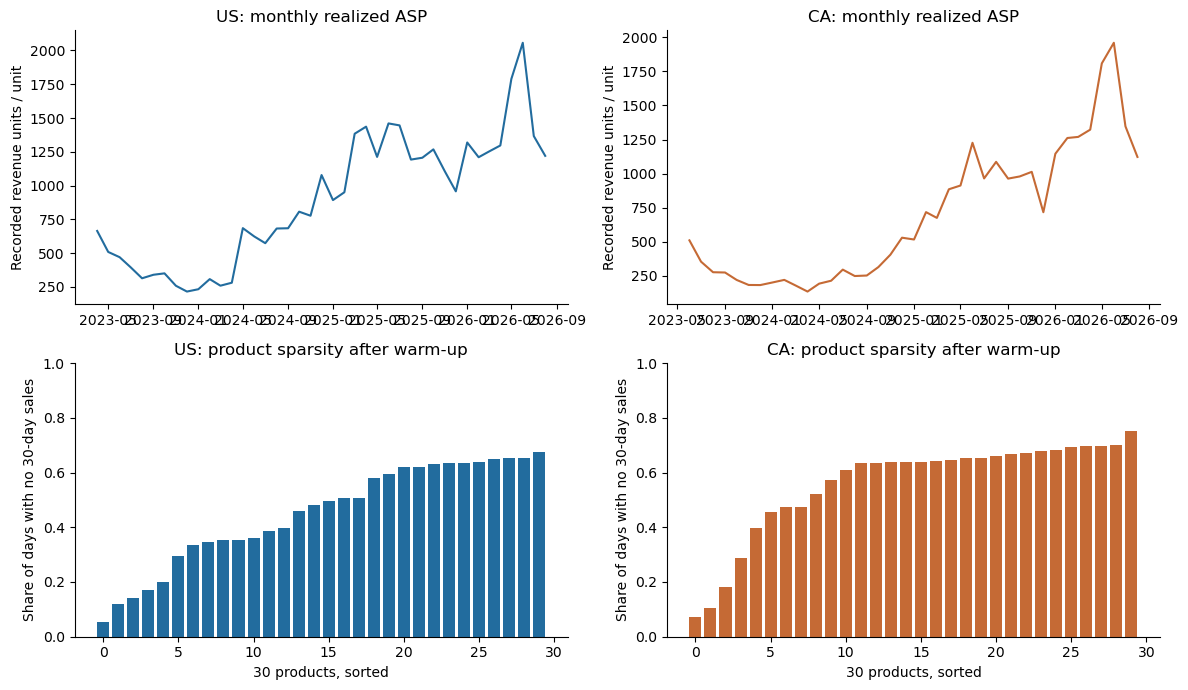

In [4]:
fig, axes=plt.subplots(2,2,figsize=(12,7))
for j,(c,p) in enumerate(panels.items()):
    monthly=clean[c].groupby(clean[c].date.dt.to_period('M')).agg(units=('order_units','sum'),revenue=('revenue','sum'))
    axes[0,j].plot(monthly.index.to_timestamp(),monthly.revenue/monthly.units,color=['#226c9e','#c56a35'][j])
    axes[0,j].set(title=f'{c}: monthly realized ASP',ylabel='Recorded revenue units / unit')
    cov=p.loc[p.history_days.ge(180)].groupby('product_id').units_30.apply(lambda x:x.eq(0).mean()).sort_values()
    axes[1,j].bar(np.arange(len(cov)),cov.values,color=['#226c9e','#c56a35'][j])
    axes[1,j].set(title=f'{c}: product sparsity after warm-up',xlabel='30 products, sorted',ylabel='Share of days with no 30-day sales',ylim=(0,1))
plt.tight_layout(); plt.show()

## 4. Models and leakage-safe evaluation
**Benchmarks:** (1) last observed daily product ASP; (2) current rolling ASP persistence; (3) requested 0.5/0.3/0.2 blend; (4) nonnegative weights summing to one learned separately by country; (5–6) shallow histogram gradient boosting predicting log(target/current reference) with rolling sales, margin, family-relative prices, staleness and seasonality. The residual model captures conditional changes without treating high-price SKUs as interchangeable with low-price ones. Fixed modest complexity avoids a large hyperparameter search.

**New nonlinear model candidates:** Random Forest with minimum leaf sizes 10 and 30, and Extra Trees with minimum leaf size 10. All use 250 trees, maximum depth 12 and 80% of features per split. Random Forest averages bootstrap-trained decision trees; Extra Trees averages trees with randomized split thresholds. The log residual target makes price changes relative to a past-only product reference and ensures positive predictions after exponentiation. `log_reference` permits different behavior by price level without using arbitrary numeric SKU codes. Both countries are fit separately, without customer identifiers or country pooling. These models learn nonlinear thresholds and interactions in activity, trend, staleness, seasonality and family-relative prices. They do not constrain predictions to a three-weight formula.

Convex weights minimize unit-weighted squared price error plus a small pull toward default weights. Training uses raw future units as sample weights, matching the primary business-weighted assessment. The residual model caps forecast/reference ratios to [0.5,2] as a predeclared numerical guardrail; it is evaluated with that cap.

**Protocol:** last 91 calendar days reserved for test; three earlier consecutive 63-day validation folds, expanding training, 180-day feature warm-up. Training target end must be strictly before validation start, and validation targets must end before the next boundary. Choose among the new Random Forest and Extra Trees candidates using lowest average fold unit-weighted MAE (equal fold weight); exact ties follow candidate order, preferring simpler models. The fixed formula, persistence, earlier linear model and gradient boosting are benchmarks only for this revision; selection is restricted to the requested alternative model classes. This fulfills the requirement for one trained model per country, without implying ML necessarily beats the benchmarks. Refit once on all matured pre-test labels, then evaluate the historical test block. **This is the same test period already inspected in earlier notebook versions, so it is a reused historical holdout, not a fresh independent confirmation.** No test results are used to select the new tree configuration; confirm the eventual choice on a later untouched period. Historical features update as actual shipments become available, but fitted parameters stay frozen during each fold/test. This simulates recurring daily operations, not a single 91-day forecast.

Primary metric: **unit-weighted MAE** = Σ units·|forecast−ASP| / Σ units. Also report unit-weighted WAPE, RMSE, signed bias, equal-SKU relative MAE, label coverage, low-activity performance and uncertainty. Only positive future-unit weeks have an observable price target: zero-sale weeks are counted in coverage, not imputed as zero price. No random split. No same-day/future price tier, invoice totals, or target-window features.

In [5]:
FEATURES = ['family_relative','previous_relative','relative_trend','units_30','units_90',
 'transactions_30','days_since_sale','margin_rate_30','family_margin_rate_90',
 'clearance_pressure','month_sin','month_cos','log_reference']
NAMES=['last_price','rolling_30','default_blend','learned_blend','residual_small','residual_medium',
       'random_forest_leaf10','random_forest_leaf30','extra_trees_leaf10']
ML_NAMES=['random_forest_leaf10','random_forest_leaf30','extra_trees_leaf10']
def fit_model(name, train):
    if name=='learned_blend':
        X=train[['x1','x2','x3']].to_numpy(); y=train.target.to_numpy(); sw=train.future_units.to_numpy()
        scale=np.average(y*y,weights=sw)
        def loss(w): return np.average((X@w-y)**2,weights=sw)/scale+.001*np.sum((w-[.5,.3,.2])**2)
        fit=minimize(loss,[.5,.3,.2],bounds=[(0,1)]*3,constraints={'type':'eq','fun':lambda w:w.sum()-1},method='SLSQP')
        if not fit.success: raise RuntimeError(fit.message)
        return fit.x
    if name in ML_NAMES:
        cls = ExtraTreesRegressor if name.startswith('extra_trees') else RandomForestRegressor
        leaf = 30 if name.endswith('leaf30') else 10
        reg = cls(n_estimators=250,max_depth=12,min_samples_leaf=leaf,max_features=.8,
                  random_state=SEED,n_jobs=2)
        model=make_pipeline(SimpleImputer(strategy='median',add_indicator=True),reg)
        model.fit(train[FEATURES],np.log(train.target/train.current_reference),
                  **{model.steps[-1][0]+'__sample_weight':train.future_units.to_numpy()})
        return model
    if name.startswith('residual'):

        leaves,reg=(7,20) if name=='residual_small' else (15,40)
        model=make_pipeline(SimpleImputer(strategy='median',add_indicator=True),HistGradientBoostingRegressor(
            max_iter=150,max_leaf_nodes=leaves,min_samples_leaf=35,l2_regularization=reg,
            learning_rate=.05,early_stopping=False,random_state=SEED))
        model.fit(train[FEATURES],np.log(train.target/train.current_reference),
                  histgradientboostingregressor__sample_weight=train.future_units.to_numpy())
        return model
    return None
def predict(name,model,d):
    if name=='last_price': return d.last_asp.to_numpy()
    if name=='rolling_30': return d.current_reference.to_numpy()
    if name=='default_blend': return d[['x1','x2','x3']].to_numpy()@np.array([.5,.3,.2])
    if name=='learned_blend': return d[['x1','x2','x3']].to_numpy()@model
    return d.current_reference.to_numpy()*np.exp(model.predict(d[FEATURES]).clip(np.log(.5),np.log(2)))
def metrics(d,pred):
    y=d.target.to_numpy(); u=d.future_units.to_numpy(); e=np.asarray(pred)-y
    return dict(n=len(d),products=d.product_id.nunique(),weighted_MAE=np.average(abs(e),weights=u),
      WAPE=np.sum(u*abs(e))/np.sum(u*y),weighted_RMSE=np.sqrt(np.average(e**2,weights=u)),
      bias=np.average(e,weights=u),macro_SKU_relative_MAE=pd.Series(abs(e)/y,index=d.index).groupby(d.product_id).mean().mean())
def eligible(p):
    return p.loc[p.history_days.ge(MIN_HISTORY)&p.current_reference.gt(0)&p.target.gt(0)&np.isfinite(p.target)].copy()
fold_rows=[]; split_rows=[]; samples={}; boundaries={}
for c,p in panels.items():
    last=clean[c].date.max(); test_start=last-pd.Timedelta(days=TEST_DAYS-1)
    anchor=p.date.min()+pd.Timedelta(days=MIN_HISTORY)
    s=p.loc[((p.date-anchor).dt.days%HORIZON).eq(0)&p.target_end.le(last)].copy()
    samples[c]=s; boundaries[c]=test_start
    starts=[test_start-pd.Timedelta(days=FOLD_DAYS*k) for k in [3,2,1]]
    for fold,start in enumerate(starts,1):
        end=start+pd.Timedelta(days=FOLD_DAYS)
        tr=eligible(s.loc[s.target_end.lt(start)])
        va=eligible(s.loc[s.date.ge(start)&s.target_end.lt(end)])
        assert tr.target_end.max()<va.date.min()
        split_rows.append(dict(country=c,fold=fold,train_labels=len(tr),validation_labels=len(va),
                               validation_start=start,validation_end=end-pd.Timedelta(days=1)))
        for name in NAMES:
            model=fit_model(name,tr); pred=predict(name,model,va)
            fold_rows.append(dict(country=c,fold=fold,model=name,**metrics(va,pred)))
fold_results=pd.DataFrame(fold_rows)
validation=fold_results.groupby(['country','model'],sort=False).weighted_MAE.agg(['mean','std']).reset_index()
display(pd.DataFrame(split_rows)); display(validation.sort_values(['country','mean']))
winners={c:validation.loc[validation.country.eq(c)&validation.model.isin(ML_NAMES)].sort_values('mean',kind='stable').iloc[0]['model'] for c in panels}
assert all(n in ML_NAMES for n in winners.values())
print('Validation-selected trained ML models:',winners)

,country,fold,train_labels,validation_labels,validation_start,validation_end
0,US,1,1428,191,2025-11-23,2026-01-24
1,US,2,1619,219,2026-01-25,2026-03-28
2,US,3,1838,89,2026-03-29,2026-05-30
3,CA,1,803,97,2025-11-23,2026-01-24
4,CA,2,912,183,2026-01-25,2026-03-28
5,CA,3,1114,59,2026-03-29,2026-05-30


,country,model,mean,std
11,CA,default_blend,156.098227,60.492210
12,CA,learned_blend,156.394360,65.367916
14,CA,residual_medium,159.482421,37.391700
17,CA,extra_trees_leaf10,161.767051,57.219307
15,CA,random_forest_leaf10,163.162379,54.606716
13,CA,residual_small,163.343552,39.287558
16,CA,random_forest_leaf30,165.003211,62.421268
10,CA,rolling_30,172.322005,57.014601
9,CA,last_price,200.910361,70.900014
3,US,learned_blend,150.354165,37.790504


Validation-selected trained ML models: {'US': 'extra_trees_leaf10', 'CA': 'extra_trees_leaf10'}


### Which signals do the new models use?
Permutation importance below is measured on the **last validation fold**, before final pre-test refitting. Each feature is shuffled within each decision date so the date structure is preserved; an increase in unit-weighted MAE indicates predictive reliance. Correlated features can share importance, and negative values can occur. This explains the model's prediction behavior, not causal price effects.

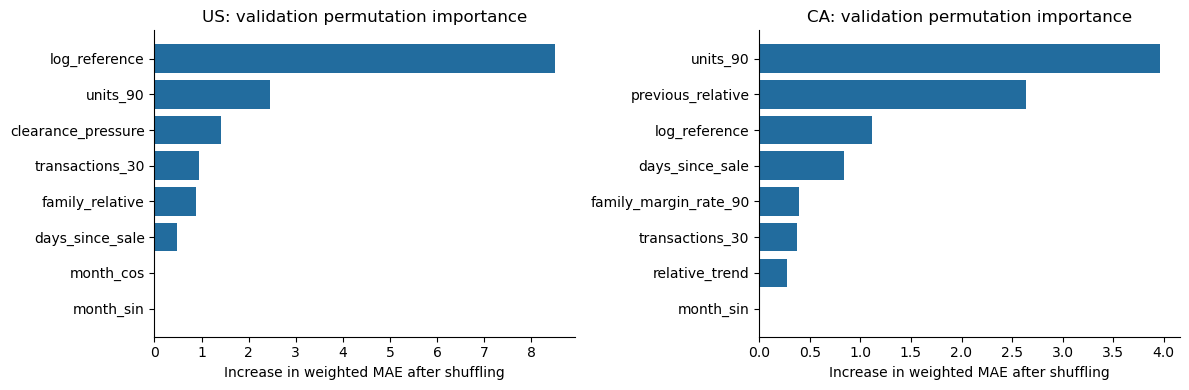

,country,feature,MAE_increase
17,CA,units_90,3.962448
14,CA,previous_relative,2.633685
25,CA,log_reference,1.114238
19,CA,days_since_sale,0.836471
21,CA,family_margin_rate_90,0.392408
18,CA,transactions_30,0.376535
15,CA,relative_trend,0.274159
23,CA,month_sin,0.000000
24,CA,month_cos,0.000000
22,CA,clearance_pressure,-0.643792


In [6]:
importance_rows=[]
for c,s in samples.items():
    end=boundaries[c]; start=end-pd.Timedelta(days=FOLD_DAYS)
    tr=eligible(s.loc[s.target_end.lt(start)])
    va=eligible(s.loc[s.date.ge(start)&s.target_end.lt(end)]).reset_index(drop=True)
    name=winners[c]; model=fit_model(name,tr)
    base=metrics(va,predict(name,model,va))['weighted_MAE']
    rng_imp=np.random.default_rng(SEED)
    for feature in FEATURES:
        changes=[]
        for repeat in range(3):
            shuffled=va.copy()
            for _,ids in shuffled.groupby('date').groups.items():
                shuffled.loc[ids,feature]=rng_imp.permutation(shuffled.loc[ids,feature].to_numpy())
            changes.append(metrics(shuffled,predict(name,model,shuffled))['weighted_MAE']-base)
        importance_rows.append(dict(country=c,feature=feature,MAE_increase=np.mean(changes)))
importance=pd.DataFrame(importance_rows)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,c in zip(axes,['US','CA']):
    z=importance.loc[importance.country.eq(c)].nlargest(8,'MAE_increase').sort_values('MAE_increase')
    ax.barh(z.feature,z.MAE_increase,color='#226c9e');ax.axvline(0,color='gray',lw=.7)
    ax.set(title=f'{c}: validation permutation importance',xlabel='Increase in weighted MAE after shuffling')
plt.tight_layout();plt.show()
display(importance.sort_values(['country','MAE_increase'],ascending=[True,False]))

## 5. Historical holdout assessment and uncertainty
All candidates are shown for transparent comparison; the deployed choice remains the validation-selected model even if a different test candidate ranks first. A paired moving-block bootstrap resamples consecutive four-week blocks of test origins, retaining all products within each origin. This partially accounts for serial and cross-product dependence; roughly 13 test origins still provide limited precision. Intervals describe this cohort and period, not causal business impact.

In [7]:
test_rows=[]; fitted={}; predictions={}; weight_rows=[]
for c,s in samples.items():
    start=boundaries[c]; tr=eligible(s.loc[s.target_end.lt(start)])
    te=eligible(s.loc[s.date.ge(start)])
    assert tr.target_end.max()<te.date.min()
    out=te.copy(); fitted[c]={}
    for name in NAMES:
        m=fit_model(name,tr); fitted[c][name]=m
        pred=predict(name,m,te); out[name]=pred
        test_rows.append(dict(country=c,model=name,selected=name==winners[c],**metrics(te,pred)))
        if name=='learned_blend': weight_rows.append(dict(country=c,current_30=m[0],family_90=m[1],previous_90=m[2]))
    predictions[c]=out
results=pd.DataFrame(test_rows)
display(pd.DataFrame(weight_rows)); display(results.sort_values(['country','weighted_MAE']))
coverage=[]
for c,s in samples.items():
    te=s.loc[s.date.ge(boundaries[c])&s.history_days.ge(MIN_HISTORY)]
    coverage.append(dict(country=c,decision_rows=len(te),priced_labels=len(eligible(te)),
         no_future_sales=int(te.future_units.eq(0).sum()),no_prior_reference=int(te.current_reference.isna().sum()),
         label_coverage=len(eligible(te))/len(te)))
display(pd.DataFrame(coverage))
rng=np.random.default_rng(SEED)
for c,d in predictions.items():
    name=winners[c]; dates=np.sort(d.date.unique()); n=len(dates)
    def gain(z):
        base=np.average(abs(z.rolling_30-z.target),weights=z.future_units)
        chosen=np.average(abs(z[name]-z.target),weights=z.future_units)
        return 1-chosen/base
    boot=[]
    for _ in range(1000):
        ids=[]
        while len(ids)<n:
            a=int(rng.integers(0,max(n-4+1,1))); ids.extend(range(a,min(a+4,n)))
        z=pd.concat([d.loc[d.date.eq(dates[i])] for i in ids[:n]],ignore_index=True)
        boot.append(gain(z))
    lo,hi=np.quantile(boot,[.025,.975])
    print(f'{c}: {name}; MAE improvement vs rolling persistence {gain(d):.1%}; block-bootstrap 95% interval [{lo:.1%}, {hi:.1%}]')
    for label,mask in [('low recent activity (<10 units / 30d)',d.units_30.lt(10)),('higher activity',d.units_30.ge(10))]:
        if mask.any(): print(label,metrics(d.loc[mask],d.loc[mask,name]))

,country,current_30,family_90,previous_90
0,US,0.749457,0.190373,0.060170
1,CA,0.629040,0.356574,0.014386


,country,model,selected,n,products,weighted_MAE,WAPE,weighted_RMSE,bias,macro_SKU_relative_MAE
16,CA,random_forest_leaf30,False,162,27,119.633352,0.095868,240.328460,-65.132379,0.130652
15,CA,random_forest_leaf10,False,162,27,121.568207,0.097418,233.934845,-67.510409,0.129728
17,CA,extra_trees_leaf10,True,162,27,124.586286,0.099837,242.362067,-63.586502,0.134372
10,CA,rolling_30,False,162,27,129.185021,0.103522,242.246038,-1.741048,0.133989
11,CA,default_blend,False,162,27,134.808705,0.108029,242.714763,-30.394626,0.127639
13,CA,residual_small,False,162,27,136.155346,0.109108,242.610516,-79.476069,0.144401
12,CA,learned_blend,False,162,27,145.392258,0.116510,257.499769,21.538699,0.125551
14,CA,residual_medium,False,162,27,147.047505,0.117836,254.241751,-95.788571,0.151466
9,CA,last_price,False,162,27,153.667643,0.123141,300.726943,-20.628617,0.160531
3,US,learned_blend,False,168,23,102.701951,0.078978,186.724268,-22.365542,0.112868


,country,decision_rows,priced_labels,no_future_sales,no_prior_reference,label_coverage
0,US,390,168,222,0,0.430769
1,CA,360,162,198,0,0.450000


US: extra_trees_leaf10; MAE improvement vs rolling persistence 2.8%; block-bootstrap 95% interval [-27.4%, 10.7%]
low recent activity (<10 units / 30d) {'n': 30, 'products': 21, 'weighted_MAE': np.float64(343.7394537870375), 'WAPE': np.float64(0.24380046033399722), 'weighted_RMSE': np.float64(465.90787592042676), 'bias': np.float64(-330.6570012535344), 'macro_SKU_relative_MAE': np.float64(0.21470744054474597)}
higher activity {'n': 138, 'products': 23, 'weighted_MAE': np.float64(87.40126429953153), 'WAPE': np.float64(0.06781055724731526), 'weighted_RMSE': np.float64(170.6100031946402), 'bias': np.float64(-50.37644086736739), 'macro_SKU_relative_MAE': np.float64(0.09904055554631312)}
CA: extra_trees_leaf10; MAE improvement vs rolling persistence 3.6%; block-bootstrap 95% interval [-9.7%, 4.7%]
low recent activity (<10 units / 30d) {'n': 51, 'products': 27, 'weighted_MAE': np.float64(256.9327079629349), 'WAPE': np.float64(0.18862527386286546), 'weighted_RMSE': np.float64(445.349402927665

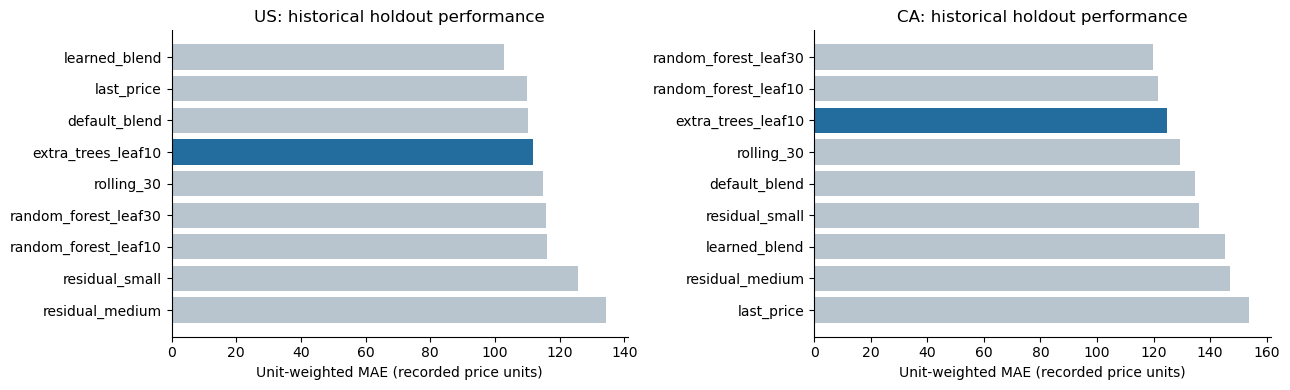

/var/folders/gq/glzjr1bd5vq23xf6yptyc8wc0000gn/T/ipykernel_10154/3225192694.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sku=d.groupby('product_id').apply(lambda z:pd.Series({'actual':np.average(z.target,weights=z.future_units),
/var/folders/gq/glzjr1bd5vq23xf6yptyc8wc0000gn/T/ipykernel_10154/3225192694.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sku=d.groupby('product_id').apply(lambda z:p

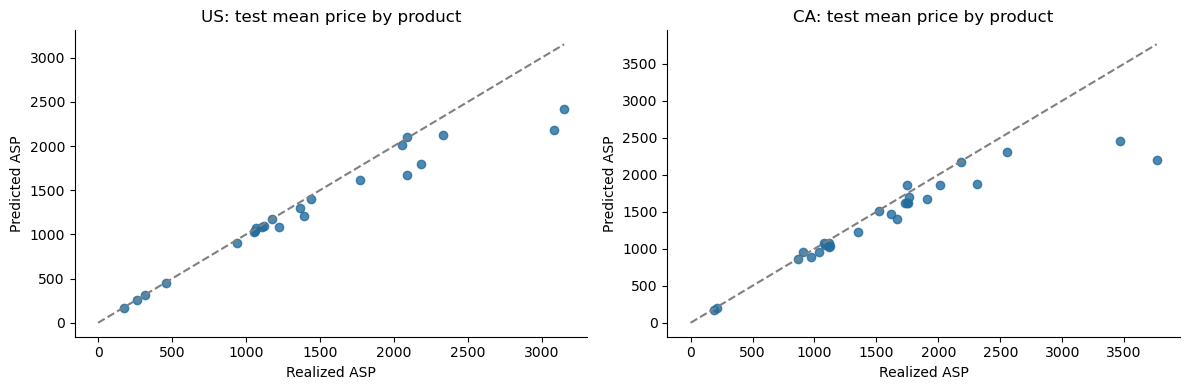

In [8]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,(c,d) in zip(axes,predictions.items()):
    r=results.loc[results.country.eq(c)].sort_values('weighted_MAE')
    ax.barh(r.model,r.weighted_MAE,color=['#226c9e' if n==winners[c] else '#b8c5cf' for n in r.model])
    ax.invert_yaxis();ax.set(title=f'{c}: historical holdout performance',xlabel='Unit-weighted MAE (recorded price units)')
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,(c,d) in zip(axes,predictions.items()):
    n=winners[c]
    sku=d.groupby('product_id').apply(lambda z:pd.Series({'actual':np.average(z.target,weights=z.future_units),
            'predicted':np.average(z[n],weights=z.future_units)}))
    ax.scatter(sku.actual,sku.predicted,color='#226c9e',alpha=.8)
    lim=max(sku.max());ax.plot([0,lim],[0,lim],color='gray',ls='--'); ax.set(title=f'{c}: test mean price by product',xlabel='Realized ASP',ylabel='Predicted ASP')
plt.tight_layout();plt.show()

## 6. Daily recommendation table and final country fits
After assessment, refit each selected model on every matured weekly target available through that country's last observed shipment date. Recommend as of the following day. The raw model prediction is the suggested reference; price change is prediction minus current rolling reference. The current reference is a **realized ASP proxy**, not a list price.

A separate operational proposal caps moves to ±10% and holds stale (>30 days without a sale), missing-reference, and very sparse (<5 units/30 days) products for review. These are explicit illustrative policy assumptions, not learned optimization. Raw forecast accuracy above does not validate this policy. Provided margin can imply a historical cost proxy `(rolling revenue − rolling margin)/rolling units`; it is diagnostic only, since accounting/currency alignment and prospective cost are unconfirmed. No automatic margin floor is imposed. No discount is mechanically triggered by the slowdown flag.

Recommendations include product and family rolling measures, missing return rates, uncertainty flags, both raw and guarded price changes, and the learned baseline formula component. All prices remain in recorded revenue units.

In [9]:
production_models={}; recommendations={}
for c,p in panels.items():
    last=clean[c].date.max(); name=winners[c]
    tr=eligible(samples[c].loc[samples[c].target_end.le(last)])
    model=fit_model(name,tr); production_models[c]={'name':name,'model':model,'as_of':last+pd.Timedelta(days=1)}
    live=p.loc[p.date.eq(last+pd.Timedelta(days=1))].copy()
    live['country']=c; live['model']=name
    ok=live.current_reference.gt(0)
    live['suggested_price']=np.nan
    live.loc[ok,'suggested_price']=predict(name,model,live.loc[ok])
    # Formula output uses final learned blend even when the ML challenger wins selection.
    blend=fit_model('learned_blend',tr)
    live['learned_formula_price']=live[['x1','x2','x3']].to_numpy()@blend
    live['default_formula_price']=live[['x1','x2','x3']].to_numpy()@np.array([.5,.3,.2])
    live['price_change']=live.suggested_price-live.current_reference
    live['price_change_pct']=live.price_change/live.current_reference
    live['historical_unit_cost_proxy']=(live.revenue_30-live.margin_30)/live.units_30.replace(0,np.nan)
    live['review_required']=(~ok)|live.days_since_sale.gt(30)|live.units_30.lt(5)
    live['guarded_price']=live.suggested_price.clip(lower=live.current_reference*.9,upper=live.current_reference*1.1)
    live.loc[live.review_required,'guarded_price']=live.current_reference
    live['guarded_change']=live.guarded_price-live.current_reference
    recommendations[c]=live
    print(c,'production model:',name,'as of',live.date.iloc[0].date(),'learned blend weights:',blend.round(4))
    display(live[['product_id','current_reference','suggested_price','price_change_pct','guarded_price',
                  'units_30','sales_trend','clearance_pressure','review_required']].round(3))
    assert len(live)==30
    assert np.allclose(live.price_change,live.suggested_price-live.current_reference,equal_nan=True)
print('Both country recommendation tables contain all 30 products. Fitted objects are available in production_models.')

US production model: extra_trees_leaf10 as of 2026-08-30 learned blend weights: [0.7559 0.173  0.0711]


,product_id,current_reference,suggested_price,price_change_pct,guarded_price,units_30,sales_trend,clearance_pressure,review_required
1244,00RN3110HH,1660.200,1656.756,-0.002,1660.200,0.0,0.0,1,True
2489,01VKBDM3YP,1352.343,1300.270,-0.039,1300.270,238.0,119.0,0,False
3734,03DF114WYO,1788.594,1744.578,-0.025,1744.578,586.0,-533.0,1,False
4979,04OA900WKL,1664.000,1663.377,-0.000,1664.000,0.0,0.0,1,True
6224,06AS870MKS,1072.623,1059.672,-0.012,1059.672,191.0,62.0,0,False
7469,10TBMCG2LC,3484.709,3116.686,-0.106,3136.238,14.0,-42.0,1,False
8714,13BASGW8QU,253.363,244.682,-0.034,253.363,0.0,0.0,1,True
9959,15NG0502TB,874.000,981.952,0.124,874.000,0.0,0.0,1,True
11204,16T0MJI6WJ,2940.151,2765.738,-0.059,2765.738,64.0,14.0,1,False
12449,17HFYLR9WD,2330.816,2179.504,-0.065,2179.504,117.0,117.0,0,False


CA production model: extra_trees_leaf10 as of 2026-08-30 learned blend weights: [0.621  0.2953 0.0838]


,product_id,current_reference,suggested_price,price_change_pct,guarded_price,units_30,sales_trend,clearance_pressure,review_required
1173,00RN3110HH,1619.852,1813.497,0.120,1619.852,0.0,0.0,1,True
2347,02XJSFY3QN,1745.396,1724.414,-0.012,1724.414,62.0,6.0,0,False
3521,03DF114WYO,1710.859,1680.199,-0.018,1680.199,109.0,-31.0,1,False
4695,04OA900WKL,1549.400,1750.993,0.130,1549.400,0.0,0.0,1,True
5869,07IB9389VQ,1066.537,1022.282,-0.041,1022.282,89.0,4.0,0,False
7043,10TBMCG2LC,2666.175,2321.835,-0.129,2666.175,2.0,-16.0,1,True
8217,13BASGW8QU,217.138,202.685,-0.067,217.138,0.0,-8.0,1,True
9391,16CHOUW4TD,1699.999,1684.286,-0.009,1684.286,59.0,21.0,0,False
10565,16T0MJI6WJ,1960.482,1639.438,-0.164,1764.433,6.0,-9.0,1,False
11739,17D4481BEM,1015.521,976.915,-0.038,976.915,216.0,216.0,0,False


Both country recommendation tables contain all 30 products. Fitted objects are available in production_models.


## 7. Interpretation and limits
The following conclusions are generated from actual executed results. Use validation-selected models for the two country baselines. The final models in this revision are nonlinear Random Forest or Extra Trees regressors, selected separately per country on validation. The learned linear blend remains a benchmark. Sharing an estimator class does not share fitted trees across countries. Model complexity is not a guarantee of superior test accuracy: compare all baselines and treat the reused historical holdout as provisional evidence.

- WAPE describes price error weighted by units and price level; it does not measure demand forecast accuracy or revenue uplift. Equal-SKU error helps reveal domination by large products.
- Family mix, promotions, bulk orders and changing customer/channel composition can move realized ASP without a list-price change. Target-week units are used only for supervised training/evaluation weights, never as prediction inputs.
- Zero recorded sales do not distinguish no demand from no inventory. Slowdown and low units are monitoring signals, not sufficient grounds to clear stock.
- Returns are unavailable; do not interpret the missing return-rate columns as measured zero. Family rollups omit unselected products.
- The final shipment date is not evidence that the calendar period is complete. Confirm extraction completeness before deployment. Historical selection bias and synthesized source filenames limit real-world claims.
- Before live pricing: obtain verified local currency/cost definitions, current list prices, inventory, return events and randomized price-response evidence. Monitor rolling error, price-change frequency, coverage and margin after deployment; retrain on a scheduled cadence using matured labels.

Optional exports below are disabled by default. The notebook contains the complete executed assessment and live tables without requiring external model artifacts.

In [10]:
for c in panels:
    r=results.loc[results.country.eq(c)&results.model.eq(winners[c])].iloc[0]
    base=results.loc[results.country.eq(c)&results.model.eq('rolling_30')].iloc[0]
    print(f"{c} — selected {winners[c]}: test weighted MAE {r.weighted_MAE:.2f}; WAPE {r.WAPE:.1%}; "
          f"bias {r.bias:.2f}; {int(r.n)} labeled product-weeks; "
          f"MAE change vs persistence {r.weighted_MAE/base.weighted_MAE-1:+.1%}.")
EXPORT = False
if EXPORT:
    import pickle
    out=Path('baseline_outputs');out.mkdir(exist_ok=True)
    results.to_csv(out/'test_metrics.csv',index=False)
    fold_results.to_csv(out/'validation_metrics.csv',index=False)
    for c in panels:
        recommendations[c].to_csv(out/f'{c}_daily_recommendations.csv',index=False)
        predictions[c].to_csv(out/f'{c}_test_predictions.csv',index=False)
        with open(out/f'{c}_model.pkl','wb') as f:
            pickle.dump({'model':production_models[c],'features':FEATURES,'sklearn_version':sklearn.__version__},f)
    print('Exported metrics, full daily recommendation tables, test forecasts and model bundles.')

US — selected extra_trees_leaf10: test weighted MAE 111.73; WAPE 8.6%; bias -76.98; 168 labeled product-weeks; MAE change vs persistence -2.8%.
CA — selected extra_trees_leaf10: test weighted MAE 124.59; WAPE 10.0%; bias -63.59; 162 labeled product-weeks; MAE change vs persistence -3.6%.
